# Homework 10: Monte Carlo integration and simulation

**Course title:** Computer Simulation Methods in Physics (Phys 4071/5071; Fall 2024)  
**This homework assignment is due November 24, 2025, at 6 pm.** Note the extended deadline!   
(Submission via the shared `GitHub` repository.)

**Before you submit your homework, make sure that you click `Kernel > Restart & Run All`**.

## Monte Carlo Integration

a) Write a `Python` program to evaluate the integral 

$$ 
I = \int_0^2 \sin^2 \left ( { 1 \over x(2-x)} \right ) dx 
$$

using the **hit-or-miss Monte Carlo method** with a sufficient number of sampled points $N$ so that the error is less than $10^{-3}$.

b) Estimate the integral again using the mean value method with a sufficient  number of sampled points $N$ so that the error is less than $10^{-3}$. You should find that the mean value method requires a smaller number of sampled points.

I =  1.45136 +/- 2.899135710793693e-04


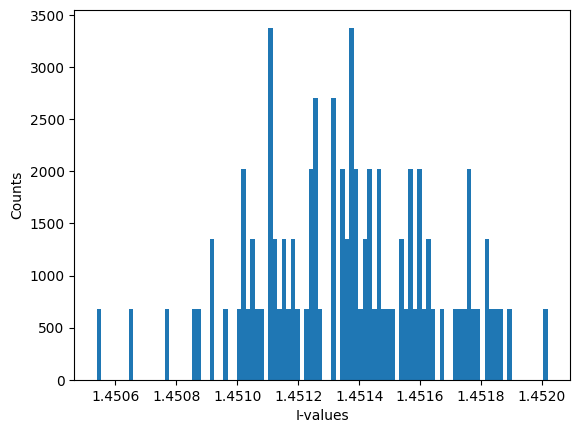

In [1]:
# Monte Carlo Integration Part a.) 

# hit and miss method
import numpy.random as rnd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import scipy as sp 


# function of integral 
f = lambda x: np.sin(1.0 / (x * (2.0 - x)))**2


# number of samples 
N = 10000000 # per integration 
M = 100 # per runs 

# boundary terms 
eps = 1e-6
a, b = (0.0 + eps), (2.0 - eps) 
length = b - a 


I_mc = [] 
for i in range(M):
    #rectangle bounds
    x = a + length * rnd.rand(N) 
    y_max = 1.0
    y = y_max * rnd.rand(N) 
    #integration 
    frac = np.mean(y <= f(x)) 
    area = length * y_max  
    I_mc.append(frac * area)


plt.hist(I_mc, bins=100, density=True)
plt.xlabel("I-values") 
plt.ylabel("Counts")
#average integral
I_av = np.mean(I_mc)  # or likewise, np.sum(I)/M

# standard deviation
std = np.std(I_mc) # or likewise, np.sqrt(sum((I - I_av)**2)/M)

print(f"I = {I_av: .5f} +/- {std:1.15e}")

I =  1.45150 +/- 5.130699336695705e-04


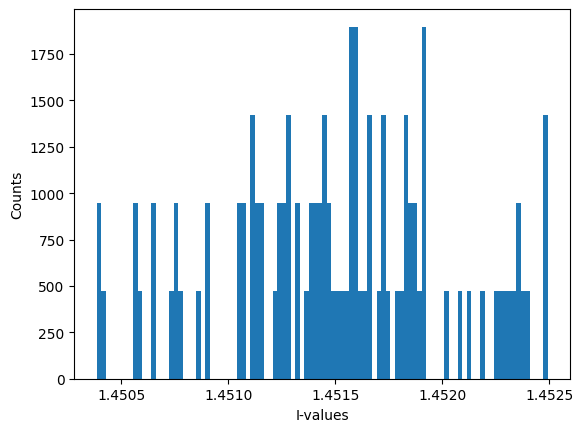

In [2]:
# Monte Carlo Integration Part b.) 

# hit and miss method
import numpy.random as rnd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import scipy as sp 


# function of integral 
f = lambda x: np.sin(1.0 / (x * (2.0 - x)))**2

# number of samples 
N = 1000000 # per integration 
M = 100 # per runs 

# boundary terms 
eps = 1e-6
a, b = (0.0 + eps), (2.0 - eps) 
length = b - a 


I_mc = [] 
for i in range(M):
    x = a + (b-a) * rnd.random(N)
    values = f(x)
    estimate = (b-a) * np.mean(values)
    I_mc.append(estimate)


plt.hist(I_mc, bins=100, density=True)
plt.xlabel("I-values") 
plt.ylabel("Counts")
#average integral
I_av = np.mean(I_mc)  # or likewise, np.sum(I)/M

# standard deviation
std = np.std(I_mc) # or likewise, np.sqrt(sum((I - I_av)**2)/M)

print(f"I = {I_av: .5f} +/- {std:1.15e}")

## Volume of an $n$-dimensional sphere
The equation for the volume of an $n$-dimensional sphere of radius $R$ is given by 

$$ V_n(R) = {\pi^{n\over 2}\over \Gamma({n \over 2} + 1)}R^n \,,$$

where $\Gamma(x)$ denotes Euler's Gamma function. 

a) Evaluate this equation using library functions (for example, using `scipy`) and plot the volume versus the dimension $n$ at $R=1$.

b) Instead of using the equation above, use Monte Carlo integration to calculate the volume of the $n$-dimensinal sphere and verify the equation above for $n=1,2,\ldots,10$ and $R=1$. Plot the volume as a function of $n$ and compare with a).

 n      V_n
 1 1.000000
 2 2.000000
 3 3.141593
 4 4.188790
 5 4.934802
 6 5.263789
 7 5.167713
 8 4.724766
 9 4.058712
10 3.298509


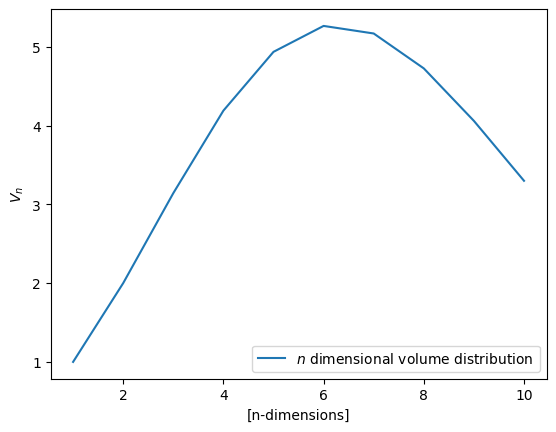

In [3]:
#Volume of n-dimensional sphere Part a.) 
import numpy.random as rnd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import scipy as sp 
from scipy.special import gamma
import pandas as pd 

#Function for n-dimensional volume
def V(n,R): 
    ''' This function just evaluates the n-dimensional 
        volume analytically. 

    Parameter: 
    ----------
    n,R: numpy array and float 
    The inputs are the n-dimensions and the radius magnitude. 

    Return: 
    -------
    numpy array or List 
    The are volume values corresponding to particular dimensions.  
    '''
    V_n = ((np.pi**(n/2.0))/(gamma((n/2.0) + 1.0)))*(R**n)
    return V_n 



#calculating volumes 
R = 1.0 
n_vals = np.arange(1,11) 
v = [] 
for n in range(len(n_vals)): 
    v.append(V(n,R))
    
    
df = pd.DataFrame({ 
    "n": n_vals,
    "V_n": v
    })

print(df.to_string(index=False)) 


# plotting of n-dimensional volume 
plt.plot(n_vals, v, label = rf"$n$ dimensional volume distribution") 
plt.xlabel("[n-dimensions]") 
plt.ylabel(rf"$V_n$") 
plt.legend(loc="best") 

 n     V_n
 1 2.00000
 2 3.13820
 3 4.19456
 4 4.88816
 5 5.30048
 6 5.10208
 7 4.84096
 8 3.91936
 9 3.29728
10 2.97984


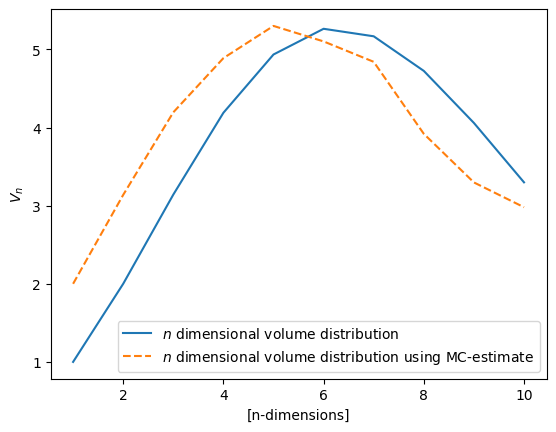

In [4]:
#Volume of n-dimensional sphere  Part b.) 

# hit and miss method
import numpy.random as rnd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import scipy as sp 


# number of samples 
N = 100000 # per integration 
R = 1.0 
V_mc = []

for n in n_vals: 
    x = rnd.uniform(-R, R, size = (N,n)) 
    r_2 = np.sum(x**2, axis = 1) 
    frac = np.mean(r_2 <= R**2) 
    v_hyper = (2*R)**n
    V_sph = frac * v_hyper 
    V_mc.append(V_sph) 


df = pd.DataFrame({ 
    "n": n_vals,
    "V_n": V_mc
    })

print(df.to_string(index=False))     
    
    

# plotting of n-dimensional volume 
plt.plot(n_vals, v, label = rf"$n$ dimensional volume distribution") 
plt.plot(n_vals, V_mc, "--", label = rf"$n$ dimensional volume distribution using MC-estimate") 
plt.xlabel("[n-dimensions]") 
plt.ylabel(rf"$V_n$") 
plt.legend(loc="best") 

## Radioactive decay chain

The isotope $^{213}\mathrm{Bi}$ decays to stable $^{209}\mathrm{Bi}$ via one of two different
routes, with probabilities and half-lives thus:

<img src="decaychain.jpg" alt="devcay-chain" width="160">

Starting with a sample consisting of $10\,000$ atoms of ${}^{213}\mathrm{Bi}$, simulate the decay of the atoms by dividing time into slices of length $\delta t=1$ s each and on each step doing the following:

1. For each atom of $^{209}\mathrm{Pb}$ in turn, decide at random, with the appropriate probability, whether it decays or not. Count the total number that decay, subtract it from the number of $^{209}\mathrm{Pb}$ atoms, and add it to the number of $^{209}\mathrm{Bi}$ atoms.
2. Now do the same for $^{209}\mathrm{Tl}$, except that decaying atoms are subtracted from the total for $^{209}\mathrm{Tl}$ and added to the total for $^{209}\mathrm{Pb}$.
3. For $^{213}\mathrm{Bi}$ the situation is more complicated: when a $^{213}\mathrm{Bi}$ atom decays you have to decide at random with the appropriate probability the route by which it decays.  Count the numbers that decay by each route and add and subtract accordingly.

Note that you have to work up the chain from the bottom like this, not down from the top, to avoid inadvertently making the same atom decay twice on a single step.

Keep track of the number of atoms of each of the four isotopes at all times for $20\,000$ seconds and make a single graph showing the four numbers as a function of time on the same axes.

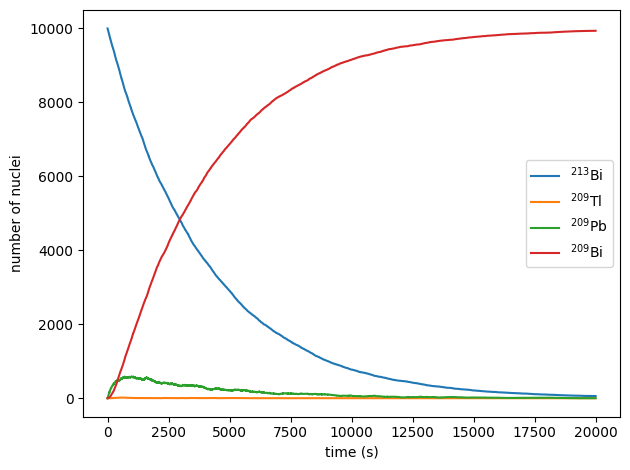

In [5]:
#Radioactive Decay Chain 
import numpy as np
import matplotlib.pyplot as plt


#define initial time step, total time, and steps 
delta_t = 1.0 #time step unit: 1s 
Total_t = 20e3 #total time 
steps = int(Total_t/delta_t) #total steps 

#half-life constants unit: s^-1
T_1_2_213_Bi = 46.0*60.0 
T_1_2_209_Tl = 2.2*60.0 
T_1_2_209_Pb = 3.3*60.0 

#half lives to decay probabilities (1 - lambdas) 
ln2 = np.log(2.0) 
P_213_Bi = (1.0 - np.exp((-ln2*delta_t)/T_1_2_213_Bi)) 
P_209_Tl = (1.0 - np.exp((-ln2*delta_t)/T_1_2_209_Tl)) 
P_209_Pb = (1.0 - np.exp((-ln2*delta_t)/T_1_2_209_Pb)) 


#branching ratios 
br_pb = 0.9791 #213-Bi to 209-Pb 
br_Tl = 0.0209 #213-Bi to 209-Pb 


#initial nuclei amount 
N_213_Bi = 10000 
N_209_Tl = 0
N_209_Pb = 0
N_209_Bi = 0

# initializing arrays 
t_vals = np.arange(steps + 1)*delta_t
Bi_213_vals = np.zeros(steps + 1, int) 
Tl_209_vals = np.zeros(steps + 1, int) 
Pb_209_vals = np.zeros(steps + 1, int) 
Bi_209_vals = np.zeros(steps + 1, int) 


#first elements 
Bi_213_vals[0] = N_213_Bi
Tl_209_vals[0] = N_209_Tl
Pb_209_vals[0] = N_209_Pb
Bi_209_vals[0] = N_209_Bi 


#Markov chain process 
for i in range(1, steps + 1): 
    #Pb-209
    decay_PB = 0
    for a in range(N_209_Pb):
        if np.random.rand() <  P_209_Pb:
            decay_PB += 1 
    N_209_Pb -= decay_PB
    N_209_Bi += decay_PB

    #Tl-209 
    decay_Tl = 0
    for a in range(N_209_Tl): 
        if np.random.rand() < P_209_Tl: 
            decay_Tl += 1
    N_209_Tl -= decay_Tl 
    N_209_Pb += decay_Tl 

    #Bi-213 
    decay_Bi = 0
    via_Tl = 0
    via_Pb = 0
    for a in range(N_213_Bi): 
        if np.random.rand() < P_213_Bi: 
            decay_Bi += 1
            if np.random.rand() < br_pb: 
                via_Pb += 1 
            else: 
                via_Tl += 1
    N_213_Bi -= decay_Bi 
    N_209_Tl += via_Tl 
    N_209_Pb += via_Pb 

    
    #recording 
    Bi_213_vals[i] = N_213_Bi
    Tl_209_vals[i] = N_209_Tl
    Pb_209_vals[i] = N_209_Pb
    Bi_209_vals[i] = N_209_Bi 


plt.plot(t_vals, Bi_213_vals, label= r"$^{213}\mathrm{Bi}$")
plt.plot(t_vals, Tl_209_vals, label= r"$^{209}\mathrm{Tl}$")
plt.plot(t_vals, Pb_209_vals, label= r"$^{209}\mathrm{Pb}$")
plt.plot(t_vals, Bi_209_vals, label= r"$^{209}\mathrm{Bi}$")
plt.xlabel("time (s)")
plt.ylabel("number of nuclei")
plt.legend(loc="best")
plt.tight_layout()
plt.show()